# Nutrimouse: reproduce Parea 2 and build executable ensemble graphs

This notebook starts with the Parea 2 experiment from
[the original Nutrimouse notebook](Nutrimouse.ipynb): the supplied measurements,
disagreement fusion, two final clustering branches, strict consensus, and
silhouette on the fused distance matrix. We replay the recorded configuration
before running a fresh genetic search. The same 40 mice have 120 gene-expression
measurements and 21 lipid measurements.

We then change preprocessing and the search objective explicitly, keeping the
Parea 2 topology and search settings fixed. Both silhouette definitions and
agreement with **genotype and diet** are reported separately. The remaining
examples demonstrate custom graph APIs and use their own illustrative settings.

You will learn to:

1. Recreate the earlier Parea 2 workflow through the graph API.
2. Optimize all four clustering blocks using the original parameter ranges.
3. Distinguish historical replay, a fresh search, and controlled variants.
4. Connect executable blocks and write reusable `nn.Module.forward()` compositions.
5. Build custom topologies, traverse them with NetworkX, and use spectral affinities.
6. Define conditional search spaces for different clustering families.

Graph nodes represent **operations in the ensemble workflow**. The matrices
carried between operations describe relationships between mice.

## 1. Install the development checkout

From the repository root, in your Python environment:

```bash
python -m pip install -e .
python -m pip install -r notebooks/requirements.txt
jupyter lab notebooks/Nutrimouse_Graphs.ipynb
```

Select the kernel for that environment and use **Restart Kernel and Run All**.
The CSV data are bundled under `notebooks/data/nutrimouse/`; execution does not
need a data download or `mvlearn`. See the [data provenance](data/nutrimouse/README.md)
for the source release, checksums, references, and attribution.

The examples use Python disagreement/agreement fusion and the graph optimizer.
The baseline passes the supplied measurements directly to clustering. Later
variants explicitly introduce per-feature standardization. Historical replay
uses the recorded Parea 2 settings and partition in the original notebook; it
does not require running its older genetic helpers or installing `mvlearn`.

In [1]:
%matplotlib inline

from pathlib import Path
import importlib.metadata
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_mutual_info_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    pairwise_distances,
    silhouette_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler

from pyrea import models, nn, optim

SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

versions = {name: importlib.metadata.version(name)
            for name in ['pyrea', 'numpy', 'scikit-learn', 'networkx', 'matplotlib']}
display(pd.Series(versions, name='Version'))

pyrea           1.0.12
numpy           1.26.4
scikit-learn     1.3.2
networkx         3.6.1
matplotlib      3.11.2
Name: Version, dtype: object

## 2. Load aligned views and evaluation labels

The CSV rows have the same ordering as `mvlearn.datasets.load_nutrimouse()`.
We assign row-based IDs (`mouse_00`, etc.) to make that alignment visible.
These are convenience IDs, not original biological identifiers.

`genotype` has two classes and `diet` has five. We will pass neither annotation
to the models or the parameter-search objective. Both annotations are used only
for reporting external agreement after configurations have been fixed or selected.

In [2]:
project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / 'notebooks/data/nutrimouse/gene.csv').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Open this notebook from within the Pyrea repository checkout.')

data_dir = project_root / 'notebooks/data/nutrimouse'
gene = pd.read_csv(data_dir / 'gene.csv')
lipid = pd.read_csv(data_dir / 'lipid.csv')
genotype = pd.read_csv(data_dir / 'genotype.csv')['genotype']
diet = pd.read_csv(data_dir / 'diet.csv')['diet']

assert gene.shape == (40, 120) and lipid.shape == (40, 21)
assert len(genotype) == len(diet) == len(gene)
assert genotype.nunique() == 2 and diet.nunique() == 5
assert np.isfinite(gene.to_numpy()).all() and np.isfinite(lipid.to_numpy()).all()

sample_ids = pd.Index(['mouse_{:02d}'.format(i) for i in range(len(gene))], name='sample')
gene.index = lipid.index = sample_ids
genotype.index = diet.index = sample_ids
inputs = {'gene': gene, 'lipid': lipid}

display(pd.DataFrame({'samples': [len(gene), len(lipid)],
                      'features': [gene.shape[1], lipid.shape[1]]}, index=['gene', 'lipid']))
display(pd.crosstab(genotype, diet))

,samples,features
gene,40,120
lipid,40,21


diet,coc,fish,lin,ref,sun
genotype,,,,,
ppar,4,4,4,4,4
wt,4,4,4,4,4


### A quick look at the two views

These are separate PCA projections after per-feature standardization. Genotype
coloring is descriptive; it is not an input to clustering or parameter selection.
The different feature spaces need not show the same separation.

`prepared_inputs` below is reserved for the **standardized variants and plots**.
The baseline continues to use `inputs`, containing the supplied measurements.

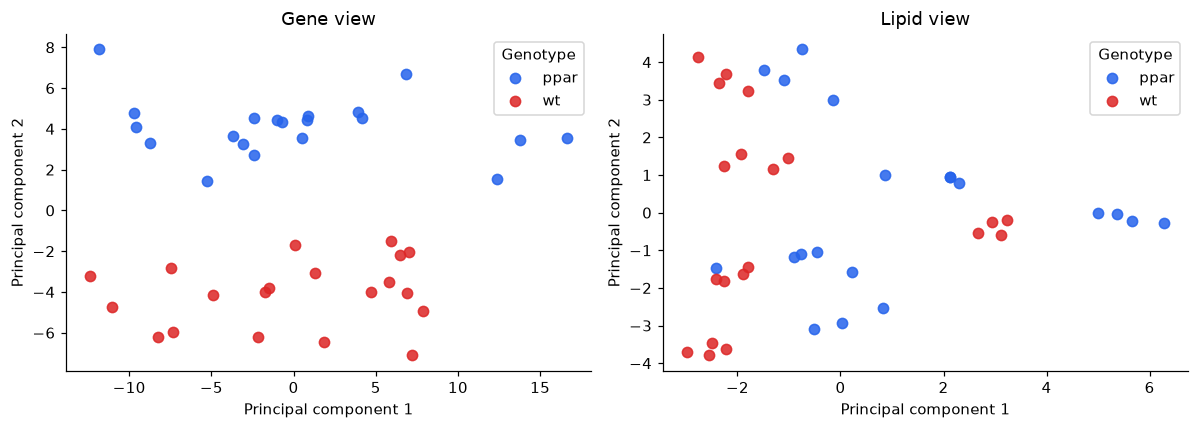

In [3]:
prepared_inputs = {
    name: pd.DataFrame(StandardScaler().fit_transform(frame),
                       index=frame.index, columns=frame.columns)
    for name, frame in inputs.items()
}
classes = sorted(genotype.unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, frame) in zip(axes, prepared_inputs.items()):
    embedding = PCA(n_components=2, svd_solver='full').fit_transform(frame)
    for label, color in zip(classes, ['#2563eb', '#dc2626']):
        mask = genotype.to_numpy() == label
        ax.scatter(embedding[mask, 0], embedding[mask, 1], label=label,
                   color=color, s=45, alpha=0.85)
    ax.set(title=name.capitalize() + ' view', xlabel='Principal component 1',
           ylabel='Principal component 2')
    ax.legend(title='Genotype')
fig.tight_layout()
plt.show()

## 3. Replay the original Parea 2 configuration

The earlier notebook selected `ward2` / `single` on the two input views with
2 / 3 clusters, followed by `complete` / `weighted` on the fused distances with
2 / 2 clusters. Fusion is disagreement, and the endpoint is strict consensus
(`k_final=None`). The graph below uses exactly these written settings and the
supplied, unscaled measurements.

There is one implementation detail to make explicit: the older hierarchical
wrapper always called Ward linkage, except that `ward2` squared the distances
first. The current wrapper honors the requested linkage. We therefore show
both the **literal recorded settings** and a second graph using the **effective
old Ward settings**. This second graph reproduces the old execution behavior
without changing the current clustering implementation.

We read the recorded Parea 2 partition from the original notebook as a replay
fixture. Adjusted Rand index (ARI) of 1 verifies the same partition independently
of cluster numbering. All displayed silhouette and annotation scores are computed
from this execution; the fixture and annotations do not enter any search fitness.

In [4]:
def partition_silhouette(distance, labels):
    count = len(np.unique(labels))
    if not 1 < count < len(labels):
        return np.nan
    return silhouette_score(distance, labels, metric='precomputed')

def fused_silhouette(output):
    return partition_silhouette(output['distance'], output['labels'])

reference_graph = models.parea_2(
    ['gene', 'lipid'], methods=('ward2', 'single'), n_clusters=2,
    precomputed_methods=('complete', 'weighted'), k_final=None, return_matrix=True,
).with_params(cluster_2__n_clusters=3)
reference_output = reference_graph(**inputs)

historical_graph = reference_graph.with_params(
    cluster_2__method='ward', recluster_1__method='ward', recluster_2__method='ward',
)
historical_output = historical_graph(**inputs)

original_notebook = json.loads((project_root / 'notebooks/Nutrimouse.ipynb').read_text())
reference_cell = next(cell for cell in original_notebook['cells']
                      if ''.join(cell['source']).startswith('labels_parea_2 = pyrea.parea_2_mv'))
reference_text = ''.join(''.join(output['text']) for output in reference_cell['outputs']
                         if output['output_type'] == 'stream')
recorded_labels = np.fromstring(reference_text.strip().strip('[]'), dtype=int, sep=' ')
assert recorded_labels.shape == (len(gene),)
assert adjusted_rand_score(recorded_labels, historical_output['labels']) == 1.0
assert adjusted_rand_score(recorded_labels, reference_output['labels']) == 1.0
assert reference_graph.graph.nodes['consensus']['block'].output_kind == nn.LABELS

replay_rows = []
for name, output in [('Recorded settings, current linkage handling', reference_output),
                     ('Effective old Ward settings', historical_output)]:
    replay_rows.append({
        'replay': name, 'clusters': len(np.unique(output['labels'])),
        'fused_silhouette': fused_silhouette(output),
        'NMI_genotype': normalized_mutual_info_score(genotype, output['labels']),
        'AMI_genotype': adjusted_mutual_info_score(genotype, output['labels']),
        'ARI_vs_recorded_partition': adjusted_rand_score(recorded_labels, output['labels']),
    })
display(pd.DataFrame(replay_rows).set_index('replay').round(4))
display(pd.Series(reference_graph.get_params(), name='Recorded Parea 2 configuration'))

,clusters,fused_silhouette,NMI_genotype,AMI_genotype,ARI_vs_recorded_partition
replay,,,,,
"Recorded settings, current linkage handling",2,0.7034,0.6844,0.6783,1.0
Effective old Ward settings,2,0.7059,0.6844,0.6783,1.0


cluster_1__clusterer       hierarchical
cluster_1__n_clusters                 2
cluster_1__method                 ward2
cluster_2__clusterer       hierarchical
cluster_2__n_clusters                 3
cluster_2__method                single
fusion__method             disagreement
fusion__normalize                 False
recluster_1__clusterer     hierarchical
recluster_1__n_clusters               2
recluster_1__method            complete
recluster_2__clusterer     hierarchical
recluster_2__n_clusters               2
recluster_2__method            weighted
Name: Recorded Parea 2 configuration, dtype: object

## 4. Run a fresh search with the original Parea 2 protocol

The baseline search uses the same supplied inputs, disagreement fusion, two
final branches and consensus, and **silhouette on the candidate's fused matrix**.
Each of the four clustering blocks searches all eight linkage choices and
cluster counts **2 through 6**, matching the original written search space.
Population **100** and **5 generations** match the earlier experiment's nominal
settings. Genotype and diet are absent from the fitness callable.

This is a fresh search using `optim.genetic_search`, with seed 42 chosen for
reproducibility. The new optimizer has its own evolutionary implementation and
elitism; the current clusterer also honors all linkage choices. A fresh optimum
need not match the earlier stochastic run or its genotype agreement. The replay
above is the direct check that the graph API can recover the recorded partition.

Caching is enabled for these deterministic operations. The log reports actual
evaluations as well as requests; these counts can differ from the earlier
optimizer. Candidate errors or degenerate partitions are recorded and penalized.

Silhouette needs between 2 and n-1 distinct clusters. Some parameter combinations
produce degenerate partitions, so their fitness is nonfinite and is penalized.
The history below shows any failed requests rather than omitting them.

In [5]:
linkages = ['single', 'complete', 'average', 'weighted',
            'centroid', 'median', 'ward', 'ward2']
parea2_template = models.parea_2(
    ['gene', 'lipid'], n_clusters=2, k_final=None, return_matrix=True,
)
parea2_space = {
    name: {'method': linkages, 'n_clusters': optim.Int(2, 6)}
    for name in ['cluster_1', 'cluster_2', 'recluster_1', 'recluster_2']
}
search_options = dict(
    population_size=100, generations=5, crossover_probability=0.7,
    mutation_probability=0.2, tournament_size=2, elitism=1,
    random_state=SEED, on_error='penalize', cache=True,
)
template_params = parea2_template.get_params()
baseline_search = optim.genetic_search(
    parea2_template, inputs, parea2_space, fitness=fused_silhouette, **search_options,
)
baseline_output = baseline_search.best_graph(**inputs)
assert parea2_template.get_params() == template_params
assert np.isclose(fused_silhouette(baseline_output), baseline_search.best_score)
assert len(baseline_search.history) == 100 + 5 * 99
assert set(baseline_search.best_graph.graph.edges) == set(parea2_template.graph.edges)
print('Fresh raw-data Parea 2 search: fused silhouette = {:.4f}'.format(baseline_search.best_score))
print('{} requests, {} evaluations, {} cache hits, {} failed requests'.format(
    len(baseline_search.history), baseline_search.n_evaluations,
    sum(row['cached'] for row in baseline_search.history),
    sum(row['status'] == 'failed' for row in baseline_search.history)))
display(pd.Series(baseline_search.best_params, name='Fresh baseline selection'))
display(pd.DataFrame(baseline_search.logbook))
failed_baseline_trials = pd.DataFrame([
    row for row in baseline_search.history if row['status'] == 'failed'
])
if not failed_baseline_trials.empty:
    display(failed_baseline_trials[['generation', 'phase', 'error', 'params']].head())

Fresh raw-data Parea 2 search: fused silhouette = 1.0000
595 requests, 466 evaluations, 129 cache hits, 1 failed requests


cluster_1__method          centroid
cluster_1__n_clusters             2
cluster_2__method          weighted
cluster_2__n_clusters             3
recluster_1__method            ward
recluster_1__n_clusters           4
recluster_2__method          median
recluster_2__n_clusters           2
Name: Fresh baseline selection, dtype: object

,generation,evaluations,cache_hits,valid,failed,generation_best,best_score,mean_score
0,0,100,0,100,0,1.0,1.0,0.663358
1,1,68,31,100,0,1.0,1.0,0.723597
2,2,75,24,99,1,1.0,1.0,0.762043
3,3,74,25,100,0,1.0,1.0,0.791674
4,4,80,19,100,0,1.0,1.0,0.835169
5,5,69,30,100,0,1.0,1.0,0.807859


,generation,phase,error,params
0,2,fitness,ValueError: fitness must return a finite score,"{'cluster_1__method': 'centroid', 'cluster_1__..."


## 5. Separate preprocessing and objective choices

First hold the recorded configuration fixed and change only its input data:
supplied measurements versus per-feature standardization. This isolates scaling
without introducing a new topology or a different selected configuration.

For a second silhouette definition, standardize each original view, calculate
Euclidean distances, divide each matrix by its positive median distance, then
average the two matrices. This **fixed view-distance matrix** is held constant
for every row. It is independent of candidate parameters and annotations.

Both silhouette definitions are useful descriptions of different geometries.
Fused silhouette measures separation in the ensemble's constructed distances;
fixed-view silhouette measures separation in the standardized measurement
geometry. Their numerical values are not interchangeable. Genotype and diet
NMI are external assessments and do not select configurations.

In [6]:
view_distances = []
for frame in prepared_inputs.values():
    distance = pairwise_distances(frame, metric='euclidean')
    np.fill_diagonal(distance, 0)
    view_distances.append(distance / np.median(distance[distance > 0]))
evaluation_distance = np.mean(view_distances, axis=0)
np.fill_diagonal(evaluation_distance, 0)
assert np.allclose(evaluation_distance, evaluation_distance.T)

def internal_score(labels):
    return partition_silhouette(evaluation_distance, labels)

def fixed_view_fitness(output):
    return internal_score(output['labels'])

def score_output(name, output):
    labels = output['labels']
    return {'experiment': name, 'clusters': len(np.unique(labels)),
            'fused_silhouette': fused_silhouette(output),
            'fixed_view_silhouette': internal_score(labels),
            'NMI_genotype': normalized_mutual_info_score(genotype, labels),
            'AMI_genotype': adjusted_mutual_info_score(genotype, labels),
            'NMI_diet': normalized_mutual_info_score(diet, labels)}

reference_scaled_output = reference_graph(**prepared_inputs)
scaling_comparison = pd.DataFrame([
    score_output('Recorded settings / raw inputs', reference_output),
    score_output('Recorded settings / standardized inputs', reference_scaled_output),
]).set_index('experiment')
display(scaling_comparison.round(4))

,clusters,fused_silhouette,fixed_view_silhouette,NMI_genotype,AMI_genotype,NMI_diet
experiment,,,,,,
Recorded settings / raw inputs,2,0.7034,0.1251,0.6844,0.6783,0.0185
Recorded settings / standardized inputs,2,0.6524,0.1881,0.0000,-0.0231,0.4744


### Reoptimize the same topology under four explicit protocols

Now vary only preprocessing and objective, keeping the template graph, all four
blocks' search spaces, seed, population and generations fixed. The raw/fused run
is the baseline above, reused here. The other three searches start independently
from the same template. Standardization takes place outside the graph, so its
connections are identical in every case.

Changing fitness changes selection and the evolutionary path. These single-seed
runs illustrate the protocol effects; they do not establish a statistical ranking
of objectives. The number of final consensus clusters is determined by the
selected partitions, so it can differ between runs.

In [7]:
protocols = {
    'Raw / fused objective': (inputs, fused_silhouette),
    'Standardized / fused objective': (prepared_inputs, fused_silhouette),
    'Raw / fixed-view objective': (inputs, fixed_view_fitness),
    'Standardized / fixed-view objective': (prepared_inputs, fixed_view_fitness),
}
protocol_searches = {'Raw / fused objective': baseline_search}
protocol_outputs = {}
for name, (data, objective) in protocols.items():
    if name not in protocol_searches:
        protocol_searches[name] = optim.genetic_search(
            parea2_template, data, parea2_space, fitness=objective, **search_options,
        )
    result = protocol_searches[name]
    output = result.best_graph(**data)
    assert np.isclose(objective(output), result.best_score)
    assert set(result.best_graph.graph.edges) == set(parea2_template.graph.edges)
    protocol_outputs[name] = output
assert parea2_template.get_params() == template_params

protocol_comparison = pd.DataFrame([
    dict(score_output(name, protocol_outputs[name]),
         requests=len(result.history), evaluations=result.n_evaluations,
         failed_requests=sum(row['status'] == 'failed' for row in result.history))
    for name, result in protocol_searches.items()
]).set_index('experiment')
display(protocol_comparison.round(4))
print('All four searches use the same topology, parameter space, seed and nominal budget.')

,clusters,fused_silhouette,fixed_view_silhouette,NMI_genotype,AMI_genotype,NMI_diet,requests,evaluations,failed_requests
experiment,,,,,,,,,
Raw / fused objective,4,1.0000,0.1063,0.2897,0.2537,0.4840,595,466,1
Standardized / fused objective,5,1.0000,0.1060,0.2526,0.1905,0.5064,595,465,6
Raw / fixed-view objective,7,0.5064,0.2342,0.5553,0.5202,0.5770,595,457,3
Standardized / fixed-view objective,13,0.7083,0.2192,0.4464,0.3658,0.6290,595,469,10


All four searches use the same topology, parameter space, seed and nominal budget.


### Read the objectives and annotations separately

High silhouette on partition-derived fused distances can coexist with modest
genotype agreement. For example, samples with identical memberships across the
input partitions have zero disagreement distance; separating these membership
patterns can produce a very high fused silhouette. This is separation in that
constructed geometry, rather than a guarantee of genotype recovery.

The fixed-view objective can favor a different biological factor, including
diet. We report both annotations for that reason. The historical replay remains
visible alongside fresh search results, even when a fresh optimum has weaker
genotype agreement. Neither annotation is used to choose a seed, fitness,
configuration, or winning run.

The plots below compare convergence **within each objective**. Each curve's
best score includes generation zero (the initial population).

When both fused-objective runs attain 1.0, their best-score curves overlap.

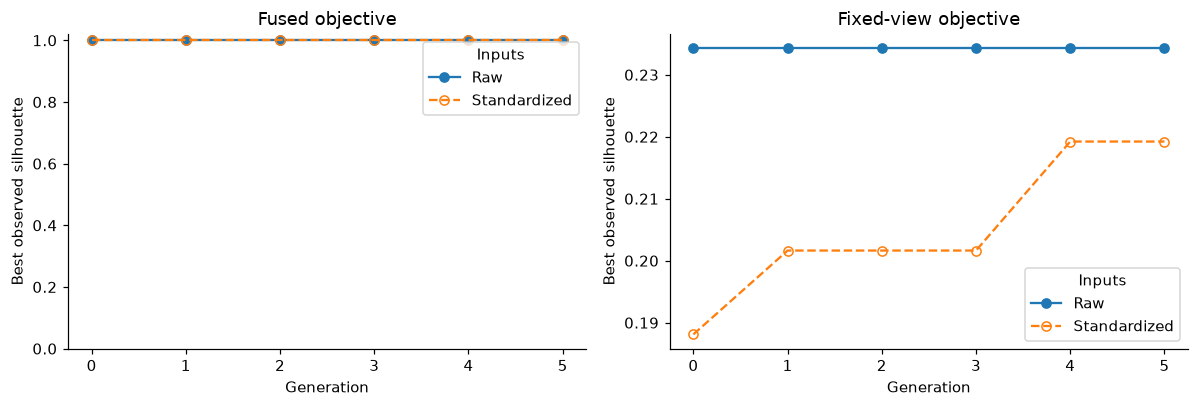

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, objective_name in zip(axes, ['fused', 'fixed-view']):
    for name, result in protocol_searches.items():
        if name.endswith('/ ' + objective_name + ' objective'):
            log = pd.DataFrame(result.logbook)
            assert log['best_score'].is_monotonic_increasing
            ax.plot(log['generation'], log['best_score'], marker='o',
                    label=name.split(' / ')[0],
                    linestyle='--' if name.startswith('Standardized') else '-',
                    markerfacecolor='none' if name.startswith('Standardized') else None)
    ax.set(title=objective_name.capitalize() + ' objective', xlabel='Generation',
           ylabel='Best observed silhouette')
    if objective_name == 'fused':
        ax.set_ylim(0, 1.02)
    ax.legend(title='Inputs')
fig.tight_layout()
plt.show()

## 6. Define a custom executable block

Subclass `nn.Block` for an indivisible operation. The declared kinds tell the
compiler what can connect to it. This block fits a fresh scaler on every call
and returns features in the same sample order; it retains no fitted state.

Clustering here is transductive: all 40 mice are analyzed together. This is not
a train/test preprocessing pipeline for predicting labels of unseen mice.

From here onward the examples explore alternative API constructions. Their
standardization, smaller topologies, and small searches are illustrative choices;
the raw-data Parea 2 protocol above is the reference experiment.

In [9]:
class Standardize(nn.Block):
    input_kinds = {'data': nn.FEATURES}
    output_kind = nn.FEATURES

    def __init__(self, name=None):
        self.name = name

    def forward(self, data):
        return StandardScaler().fit_transform(data)

## 7. Connect a graph directly

`nn.Input` is symbolic. Calling a block on it records a connection rather than
running clustering. We standardize and cluster each view, fuse the partitions
into a **distance** matrix, and recluster that matrix into two groups.

A graph can expose several named outputs. Keeping both labels and the fused
matrix makes later inspection and evaluation straightforward. The cluster counts
below are illustrative settings; a later example searches alternative settings.

In [10]:
gene_input, lipid_input = nn.Input('gene'), nn.Input('lipid')
gene_scaled = Standardize(name='gene_scale')(gene_input)
lipid_scaled = Standardize(name='lipid_scale')(lipid_input)
gene_labels = nn.Cluster('hierarchical', n_clusters=3, method='ward',
                         name='gene_cluster')(gene_scaled)
lipid_labels = nn.Cluster('hierarchical', n_clusters=3, method='complete',
                          name='lipid_cluster')(lipid_scaled)
fused_distance = nn.Fusion('disagreement', name='fusion')(gene_labels, lipid_labels)
final_labels = nn.Hierarchical(n_clusters=2, input_kind=nn.DISTANCE,
                              name='final')(fused_distance)

functional_graph = nn.Graph(inputs={'gene': gene_input, 'lipid': lipid_input},
                            outputs={'labels': final_labels, 'distance': fused_distance})
functional_result = functional_graph(**inputs)
assert functional_result['labels'].shape == (40,)
assert functional_result['distance'].shape == (40, 40)
assert np.allclose(functional_result['distance'], functional_result['distance'].T)
assert np.allclose(np.diag(functional_result['distance']), 0)
print('Final cluster sizes:', dict(zip(*np.unique(functional_result['labels'], return_counts=True))))

Final cluster sizes: {0: 21, 1: 19}


### Draw the executable topology

The helper below uses dependency depth for layout. Each box is an input or an
executable block; its color describes the kind of value it produces. We can use
the same helper for every custom or predefined topology in this notebook.

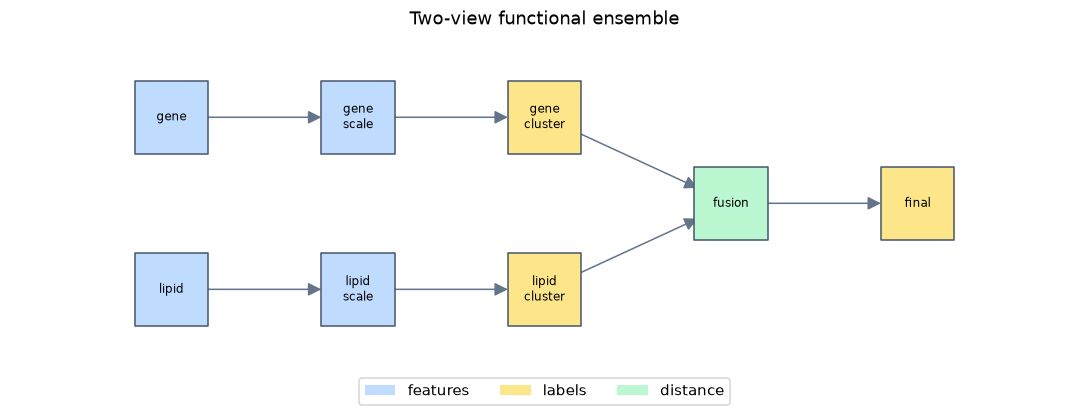

In [11]:
KIND_COLORS = {nn.FEATURES: '#bfdbfe', nn.LABELS: '#fde68a',
               nn.DISTANCE: '#bbf7d0', nn.AFFINITY: '#f5d0fe'}

def draw_workflow(model, title):
    topology = model.graph
    depth = {}
    for node in nx.topological_sort(topology):
        depth[node] = 1 + max((depth[parent] for parent in topology.predecessors(node)), default=-1)
    layers = {}
    for node, level in depth.items():
        layers.setdefault(level, []).append(node)
    positions = {node: (level, (len(nodes) - 1) / 2 - i)
                 for level, nodes in layers.items() for i, node in enumerate(nodes)}
    width = max(10, 2.0 * len(layers))
    height = max(3.8, 1.2 * max(map(len, layers.values())) + 1.5)
    fig, ax = plt.subplots(figsize=(width, height))
    colors = [KIND_COLORS[topology.nodes[node]['kind']] for node in topology]
    nx.draw_networkx_nodes(topology, positions, node_color=colors, node_shape='s',
                           node_size=2300, edgecolors='#475569', ax=ax)
    nx.draw_networkx_edges(topology, positions, node_size=2300, arrowsize=18,
                           arrowstyle='-|>', edge_color='#64748b', ax=ax)
    nx.draw_networkx_labels(topology, positions,
                            labels={node: node.replace('_', '\n').replace('.', '\n')
                                    for node in topology}, font_size=8, ax=ax)
    used_kinds = {attrs['kind'] for _, attrs in topology.nodes(data=True)}
    ax.legend(handles=[Patch(facecolor=color, label=kind)
                       for kind, color in KIND_COLORS.items() if kind in used_kinds],
              loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=len(used_kinds))
    ax.set_title(title, pad=18)
    ax.margins(x=0.15, y=0.3)
    ax.axis('off')
    fig.tight_layout()
    plt.show()

draw_workflow(functional_graph, 'Two-view functional ensemble')

## 8. Write the same topology as a reusable module

Define blocks in `__init__` and connect them in `forward()`. `compile()` infers
feature inputs from the required argument names and builds the NetworkX graph.
The block attribute names become parameter names, such as
`gene_cluster__method`. The module can also execute eagerly on arrays.

In [12]:
class NutrimouseEnsemble(nn.Module):
    def __init__(self, n_clusters=2):
        self.gene_scale = Standardize()
        self.lipid_scale = Standardize()
        self.gene_cluster = nn.Cluster('hierarchical', n_clusters=3, method='ward')
        self.lipid_cluster = nn.Cluster('hierarchical', n_clusters=3, method='complete')
        self.fusion = nn.Fusion('disagreement')
        self.final = nn.Hierarchical(n_clusters=n_clusters, input_kind=nn.DISTANCE)

    def forward(self, gene, lipid):
        gene_partition = self.gene_cluster(self.gene_scale(gene))
        lipid_partition = self.lipid_cluster(self.lipid_scale(lipid))
        distance = self.fusion(gene_partition, lipid_partition)
        return {'labels': self.final(distance), 'distance': distance}

module = NutrimouseEnsemble()
module_graph = module.compile()
module_result = module_graph(**inputs)
eager_result = module(gene.to_numpy(), lipid.to_numpy())
assert np.array_equal(module_result['labels'], functional_result['labels'])
assert np.array_equal(module_result['distance'], functional_result['distance'])
assert np.array_equal(module_result['labels'], eager_result['labels'])
display(pd.Series(module_graph.get_params(), name='Configuration'))

gene_cluster__clusterer      hierarchical
gene_cluster__n_clusters                3
gene_cluster__method                 ward
lipid_cluster__clusterer     hierarchical
lipid_cluster__n_clusters               3
lipid_cluster__method            complete
fusion__method               disagreement
fusion__normalize                   False
final__clusterer             hierarchical
final__n_clusters                       2
final__method                        ward
Name: Configuration, dtype: object

### Validate sample alignment

DataFrames let the executor check sample identifiers before any block executes.
Reversing just one view is rejected instead of silently combining different mice.
Bare NumPy arrays use positional alignment; you can attach identifiers explicitly
with `nn.SampleData(array, sample_ids)`.

In [13]:
try:
    module_graph(gene=gene, lipid=lipid.iloc[::-1])
except ValueError as error:
    print('Expected alignment error:', error)
else:
    raise AssertionError('Misaligned samples should have been rejected')

Expected alignment error: lipid sample identifiers/order do not match other inputs


## 9. Build a custom topology with unequal branch depths

We are not limited to Parea 1 or Parea 2. This graph uses a custom KMeans adapter,
two fusion stages, a shortcut from an early partition, and a strict-consensus
endpoint. The first fused matrix feeds two later blocks and is computed once per
run. The shortcut reaches the second fusion sooner than those deeper branches;
the executor still waits until **all** its dependencies are ready.

`nn.Function` wraps the KMeans callable. It constructs a fresh estimator per call
and fixes its random seed, rather than sharing fitted estimator state.

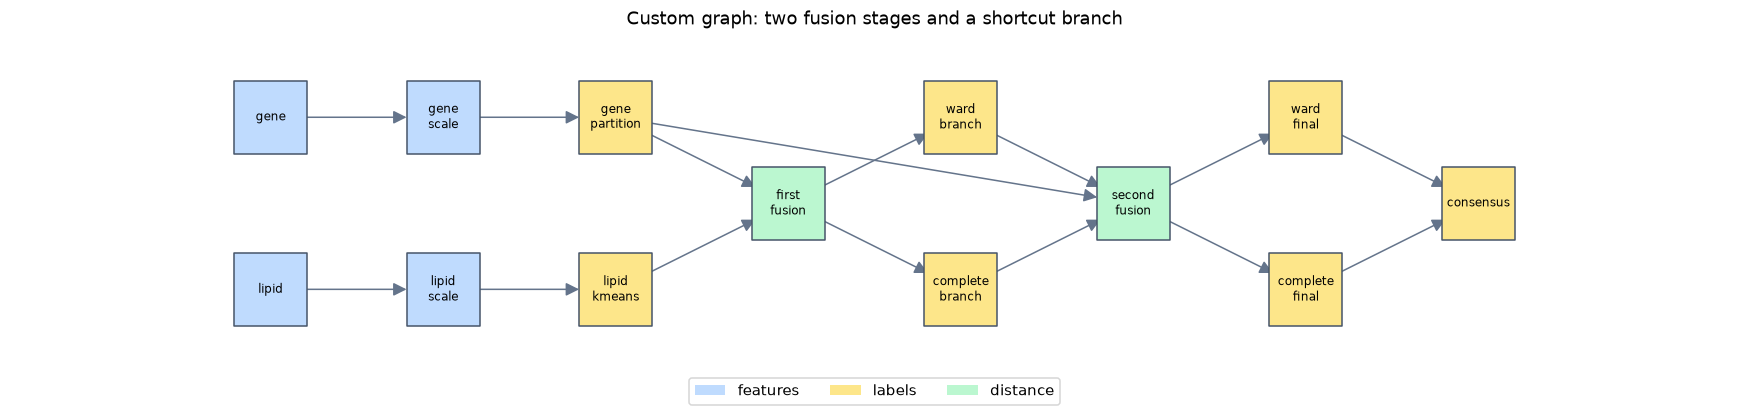

,node,kind,shape
0,gene,features,"(40, 120)"
1,lipid,features,"(40, 21)"
2,gene_scale,features,"(40, 120)"
3,lipid_scale,features,"(40, 21)"
4,gene_partition,labels,"(40,)"
5,lipid_kmeans,labels,"(40,)"
6,first_fusion,distance,"(40, 40)"
7,ward_branch,labels,"(40,)"
8,complete_branch,labels,"(40,)"
9,second_fusion,distance,"(40, 40)"


In [14]:
def kmeans_partition(data):
    return KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(data)

gene_source, lipid_source = nn.Input('gene'), nn.Input('lipid')
gene_features = Standardize(name='gene_scale')(gene_source)
lipid_features = Standardize(name='lipid_scale')(lipid_source)
early_gene = nn.Hierarchical(3, name='gene_partition')(gene_features)
early_lipid = nn.Function(kmeans_partition, {'data': nn.FEATURES},
                          output_kind=nn.LABELS, name='lipid_kmeans')(lipid_features)
first_distance = nn.Fusion(name='first_fusion')(early_gene, early_lipid)
ward_branch = nn.Hierarchical(3, method='ward', input_kind=nn.DISTANCE,
                             name='ward_branch')(first_distance)
complete_branch = nn.Hierarchical(4, method='complete', input_kind=nn.DISTANCE,
                                 name='complete_branch')(first_distance)
second_distance = nn.Fusion(name='second_fusion')(early_gene, ward_branch, complete_branch)
ward_final = nn.Hierarchical(2, method='ward', input_kind=nn.DISTANCE,
                            name='ward_final')(second_distance)
complete_final = nn.Hierarchical(3, method='complete', input_kind=nn.DISTANCE,
                                name='complete_final')(second_distance)
consensus = nn.Consensus(name='consensus')(ward_final, complete_final)
stacked_graph = nn.Graph(
    {'gene': gene_source, 'lipid': lipid_source},
    {'labels': consensus, 'distance': second_distance,
     'ward_labels': ward_final, 'complete_labels': complete_final},
)
stacked_result, intermediates = stacked_graph.run(inputs, return_intermediates=True)
draw_workflow(stacked_graph, 'Custom graph: two fusion stages and a shortcut branch')
display(pd.DataFrame([
    {'node': node, 'kind': stacked_graph.graph.nodes[node]['kind'], 'shape': value.shape}
    for node, value in intermediates.items()
]))

### Strict consensus and repeat execution

Two samples share a consensus cluster only if **every** final partition groups
them together. This is not majority voting. The common refinement can have more
clusters than either input. The output below reports the actual counts.

Intermediate results belong to one invocation. Calling the same graph again
recomputes its blocks; it does not append old partitions or reuse stale results.

In [15]:
same_consensus = stacked_result['labels'][:, None] == stacked_result['labels'][None, :]
for key in ['ward_labels', 'complete_labels']:
    same_input = stacked_result[key][:, None] == stacked_result[key][None, :]
    assert np.all(~same_consensus | same_input)
assert len(np.unique(stacked_result['labels'])) >= 3
assert np.array_equal(stacked_graph(**inputs)['labels'], stacked_result['labels'])
assert list(intermediates).count('first_fusion') == 1
print({key: len(np.unique(stacked_result[key]))
       for key in ['ward_labels', 'complete_labels', 'labels']})

{'ward_labels': 2, 'complete_labels': 3, 'labels': 4}


## 10. Traverse the workflow with NetworkX

Breadth-first search is useful for exploring reachability. It is not a general
execution schedule for merging branches of different lengths. Execution uses
topological order. Connections also retain their named input ports, so a custom
block's inputs do not depend on NetworkX neighbor ordering.

In [16]:
topology = stacked_graph.graph
bfs_order = list(nx.bfs_tree(topology, source='gene'))
execution_order = list(nx.topological_sort(topology))
assert nx.is_directed_acyclic_graph(topology)
assert all(execution_order.index(source) < execution_order.index(target)
           for source, target in topology.edges)
print('BFS from the gene input:', bfs_order)
print('Dependency order:', execution_order)
display(pd.DataFrame([
    {'source': source, 'destination': target, 'input_ports': ', '.join(attrs['ports'])}
    for source, target, attrs in topology.edges(data=True)
]))

BFS from the gene input: ['gene', 'gene_scale', 'gene_partition', 'second_fusion', 'first_fusion', 'ward_final', 'complete_final', 'ward_branch', 'complete_branch', 'consensus']
Dependency order: ['gene', 'lipid', 'gene_scale', 'lipid_scale', 'gene_partition', 'lipid_kmeans', 'first_fusion', 'ward_branch', 'complete_branch', 'second_fusion', 'ward_final', 'complete_final', 'consensus']


,source,destination,input_ports
0,second_fusion,ward_final,data
1,second_fusion,complete_final,data
2,ward_final,consensus,partitions[0]
3,complete_final,consensus,partitions[1]
4,gene_partition,second_fusion,partitions[0]
5,gene_partition,first_fusion,partitions[0]
6,ward_branch,second_fusion,partitions[1]
7,complete_branch,second_fusion,partitions[2]
8,gene_scale,gene_partition,data
9,first_fusion,ward_branch,data


## 11. Use the predefined Parea graph builders

The baseline already used the Parea 2 builder with strict consensus. Here we
demonstrate alternative builder settings over the same public blocks. Both accept
any positive number of views and use disagreement fusion. Here we apply the
same per-view standardization outside the builders; the custom graphs above
include that step inside their topology.

Parea 1 uses two method-specific branches. Parea 2 chooses an initial method per
view. `k_final=2` requests one final two-cluster solution instead of strict
consensus. `return_matrix=True` exposes the final distance matrix as well.

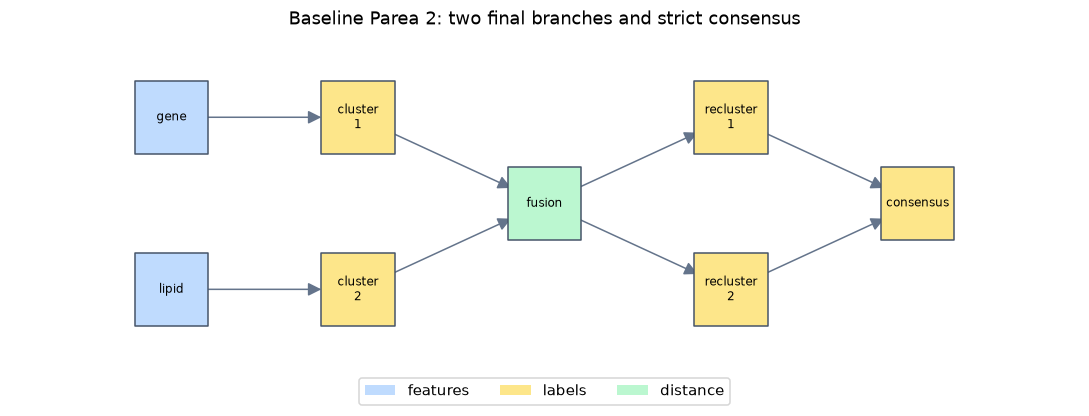

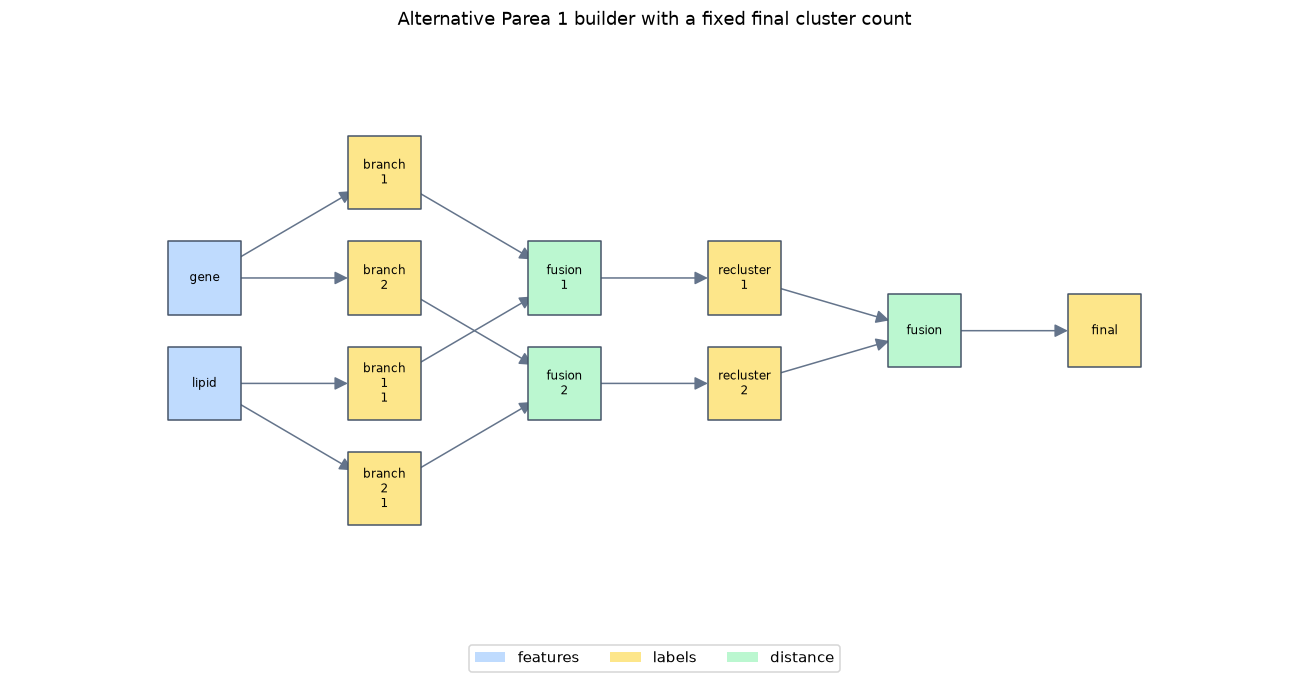

In [17]:
parea1 = models.parea_1(['gene', 'lipid'], methods=('ward', 'complete'),
                       n_clusters=3, k_final=2, return_matrix=True)
parea2 = models.parea_2(['gene', 'lipid'], methods=('ward', 'average'),
                       n_clusters=3, k_final=2, return_matrix=True)
parea1_result = parea1(**prepared_inputs)
parea2_result = parea2(**prepared_inputs)
assert parea1_result['labels'].shape == parea2_result['labels'].shape == (40,)
draw_workflow(reference_graph, 'Baseline Parea 2: two final branches and strict consensus')
draw_workflow(parea1, 'Alternative Parea 1 builder with a fixed final cluster count')

## 12. Use agreement affinities with spectral clustering

Disagreement weights are distances: larger values mean more separation.
Agreement weights are affinities: larger values mean more similarity. Here we
fuse the same view partitions using agreement and connect the result to a
spectral block that explicitly accepts **precomputed affinities**.

A square matrix's shape alone does not tell us whether it represents distances
or affinities. The graph rejects an incompatible declared connection. A
partition-derived affinity graph can also be disconnected; the component count
below helps interpret a possible spectral-clustering warning.

In [18]:
affinity = nn.Fusion('agreement', normalize=True, name='agreement')(gene_labels, lipid_labels)
spectral_labels = nn.Cluster('spectral', input_kind=nn.AFFINITY, n_clusters=2,
                             random_state=SEED, name='spectral')(affinity)
spectral_graph = nn.Graph({'gene': gene_input, 'lipid': lipid_input},
                          {'labels': spectral_labels, 'affinity': affinity})
spectral_result = spectral_graph(**inputs)
print('Affinity graph components:',
      nx.number_connected_components(nx.from_numpy_array(spectral_result['affinity'])))
assert len(np.unique(spectral_result['labels'])) == 2

try:
    nn.Hierarchical(input_kind=nn.DISTANCE)(affinity)
except TypeError as error:
    print('Expected connection error:', error)
else:
    raise AssertionError('An affinity-to-distance mismatch should have been rejected')

Affinity graph components: 1
Expected connection error: Hierarchical port data expects ('distance',), received affinity


## 13. Optional API example: a conditional parameter grid

`get_params()` exposes configuration and `with_params()` makes an independent
trial. Here we demonstrate a small conditional grid on `NutrimouseEnsemble`,
the simpler standardized topology from the API examples. We vary gene linkage
or switch that block to spectral clustering, along with final cluster count.

This example uses the **fixed-view objective** defined in the comparison above.
It has a different topology, search space and budget from the baseline Parea 2
experiment. Its score should be read with those choices in mind. Genotype and
diet remain external evaluation annotations.

In [19]:
parameter_grid = list(ParameterGrid([
    {'gene_cluster__method': ['ward', 'average'],
     'lipid_cluster__method': ['complete', 'average'],
     'final__n_clusters': [2, 3, 4]},
    {'gene_cluster__clusterer': ['spectral'],
     'gene_cluster__affinity': ['rbf'],
     'gene_cluster__gamma': [0.005, 0.01],
     'gene_cluster__n_clusters': [2, 3],
     'gene_cluster__random_state': [SEED],
     'final__n_clusters': [2, 3, 4]},
]))
baseline_params = module_graph.get_params()
trials = []
for number, params in enumerate(parameter_grid):
    candidate = module_graph.with_params(**params)
    output = candidate(**inputs)
    score = internal_score(output['labels'])
    trials.append({'trial': number, 'params': params,
                   'clusters': len(np.unique(output['labels'])),
                   'view_silhouette': score, 'valid': bool(np.isfinite(score))})
assert module_graph.get_params() == baseline_params
search_results = pd.DataFrame(trials)
valid_trials = search_results.loc[search_results['valid']].sort_values(
    ['view_silhouette', 'trial'], ascending=[False, True], kind='mergesort')
assert not valid_trials.empty
best_trial = trials[int(valid_trials.iloc[0]['trial'])]
best_graph = module_graph.with_params(**best_trial['params'])
best_result = best_graph(**inputs)
assert np.isclose(internal_score(best_result['labels']), best_trial['view_silhouette'])
print('Completed {} trials: {} valid, {} degenerate'.format(
    len(trials), int(search_results['valid'].sum()), int((~search_results['valid']).sum())))
display(valid_trials.head(8).reset_index(drop=True))
display(pd.Series(best_trial['params'], name='Selected configuration'))

Completed 24 trials: 24 valid, 0 degenerate


,trial,params,clusters,view_silhouette,valid
0,19,"{'final__n_clusters': 3, 'gene_cluster__affini...",3,0.166173,True
1,1,"{'final__n_clusters': 2, 'gene_cluster__method...",2,0.165895,True
2,23,"{'final__n_clusters': 4, 'gene_cluster__affini...",4,0.165234,True
3,13,"{'final__n_clusters': 2, 'gene_cluster__affini...",2,0.135508,True
4,16,"{'final__n_clusters': 3, 'gene_cluster__affini...",3,0.125683,True
5,21,"{'final__n_clusters': 4, 'gene_cluster__affini...",4,0.125398,True
6,12,"{'final__n_clusters': 2, 'gene_cluster__affini...",2,0.125348,True
7,15,"{'final__n_clusters': 2, 'gene_cluster__affini...",2,0.119961,True


final__n_clusters                    3
gene_cluster__affinity             rbf
gene_cluster__clusterer       spectral
gene_cluster__gamma               0.01
gene_cluster__n_clusters             3
gene_cluster__random_state          42
Name: Selected configuration, dtype: object

## 14. Optional API example: conditional genetic search

`optim.genetic_search()` accepts a compiled graph, aligned inputs, a search space
**grouped by block name**, and a fitness callable. Graph connectivity stays fixed.
The gene block has two conditional cases: hierarchical linkage choices or spectral
clustering with a log-uniform gamma. Crossover and mutation preserve each case's
active parameters, so hierarchical linkage is never passed to spectral clustering.
Integer domains include both bounds. The lipid linkage and final cluster count
are also optimized.

We reuse the fixed evaluation matrix from the controlled comparisons. Fitness receives the
graph's named-output dictionary and returns its silhouette score. The search seed
controls evolution; spectral clustering has its own seed. Score caching is enabled
because these operations and the objective are deterministic. Candidate errors or
nonfinite scores are recorded and penalized; if every candidate fails, search raises.

This example uses a different search space and evaluation budget from the grid,
including continuous gamma values. Their scores illustrate the API; this is not a
controlled comparison of genetic search against exhaustive search.

In [20]:
genetic_space = {
    'gene_cluster': [
        {'clusterer': 'hierarchical', 'method': ['ward', 'average'], 'n_clusters': 3},
        {'clusterer': 'spectral', 'affinity': 'rbf',
         'gamma': optim.Float(0.005, 0.01, log=True),
         'n_clusters': optim.Int(2, 3), 'random_state': SEED},
    ],
    'lipid_cluster': {'method': ['complete', 'average']},
    'final': {'n_clusters': optim.Int(2, 4)},
}
genetic = optim.genetic_search(
    module_graph, inputs, genetic_space,
    fitness=lambda output: internal_score(output['labels']),
    population_size=12, generations=5, random_state=SEED,
    crossover_probability=0.7, mutation_probability=0.3,
    on_error='penalize', cache=True,
)
genetic_output = genetic.best_graph(**inputs)
assert module_graph.get_params() == baseline_params
assert np.isclose(internal_score(genetic_output['labels']), genetic.best_score)
assert set(genetic.best_graph.graph.edges) == set(module_graph.graph.edges)
assert len(genetic.history) == 12 + 5 * (12 - 1)
print('Best observed fitness: {:.4f}'.format(genetic.best_score))
print('{} requests, {} actual evaluations, {} cache hits'.format(
    len(genetic.history), genetic.n_evaluations,
    sum(row['cached'] for row in genetic.history)))
display(pd.Series(genetic.best_params, name='Genetic selection'))
genetic_history = pd.DataFrame(genetic.history)
display(genetic_history[['generation', 'score', 'status', 'cached', 'phase', 'error']].head(10))

Best observed fitness: 0.1659
67 requests, 18 actual evaluations, 49 cache hits


gene_cluster__clusterer       spectral
gene_cluster__affinity             rbf
gene_cluster__gamma            0.00838
gene_cluster__n_clusters             3
gene_cluster__random_state          42
lipid_cluster__method          average
final__n_clusters                    2
Name: Genetic selection, dtype: object

,generation,score,status,cached,phase,error
0,0,0.066800,ok,False,None,None
1,0,0.099615,ok,False,None,None
2,0,0.027556,ok,False,None,None
3,0,0.153552,ok,False,None,None
4,0,0.127286,ok,False,None,None
5,0,0.106813,ok,False,None,None
6,0,0.122084,ok,False,None,None
7,0,0.127286,ok,False,None,None
8,0,0.107384,ok,False,None,None
9,0,0.027556,ok,True,None,None


### Inspect evolution and reuse the selected graph

The generation log includes the initial population (generation zero). Elitism
retains the best observed configuration. `best_params` contains active overrides
in the usual `block__parameter` format; `best_graph` is a separate configured copy,
ready to execute on aligned data. Actual evaluation counts exclude cached scores
and elites carried forward. The score is an observed optimum within this search,
with no guarantee of finding the global optimum.

,generation,evaluations,cache_hits,valid,failed,generation_best,best_score,mean_score
0,0,11,1,12,0,0.165895,0.165895,0.103948
1,1,3,8,12,0,0.165895,0.165895,0.145308
2,2,2,9,12,0,0.165895,0.165895,0.150539
3,3,2,9,12,0,0.165895,0.165895,0.147065
4,4,0,11,12,0,0.165895,0.165895,0.164866
5,5,0,11,12,0,0.165895,0.165895,0.165895


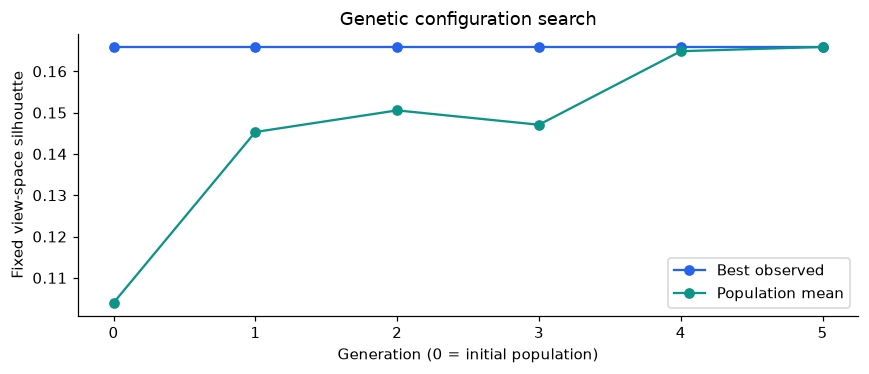

In [21]:
evolution = pd.DataFrame(genetic.logbook)
assert evolution['best_score'].is_monotonic_increasing
display(evolution)
ax = evolution.plot(x='generation', y=['best_score', 'mean_score'], marker='o',
                    figsize=(8, 3.5), color=['#2563eb', '#0d9488'])
ax.set(xlabel='Generation (0 = initial population)', ylabel='Fixed view-space silhouette',
       title='Genetic configuration search')
ax.legend(['Best observed', 'Population mean'])
plt.tight_layout()
plt.show()

reconstructed = module_graph.with_params(**genetic.best_params)
assert np.array_equal(reconstructed(**inputs)['labels'], genetic_output['labels'])

## 15. Compare all completed runs

The first rows retain the historical replay, the scaling-only comparison, and
all four Parea 2 search protocols. The remaining rows are explicitly labeled
**API examples**, which use other topologies or settings.

Every row reports the two silhouette definitions separately, plus genotype
NMI/AMI and diet NMI. All scores are computed from this execution on the same
40 mice. The recorded partition is used only to verify the replay; no historical
score is copied into the table. The annotations never enter search fitness.

Strict consensus may return more clusters than either final branch. Cluster
counts are shown so changes in granularity stay visible.

For the spectral-affinity API example, its fused affinities are explicitly
converted to distances with `AffinityToDistance` before silhouette is computed.

,clusters,fused_silhouette,fixed_view_silhouette,NMI_genotype,AMI_genotype,NMI_diet
experiment,,,,,,
Replay: effective old Ward settings / raw,2,0.7059,0.1251,0.6844,0.6783,0.0185
Replay: recorded settings / raw,2,0.7034,0.1251,0.6844,0.6783,0.0185
Replay: recorded settings / standardized,2,0.6524,0.1881,0.0000,-0.0231,0.4744
Parea 2 search: Raw / fused objective,4,1.0000,0.1063,0.2897,0.2537,0.4840
Parea 2 search: Standardized / fused objective,5,1.0000,0.1060,0.2526,0.1905,0.5064
Parea 2 search: Raw / fixed-view objective,7,0.5064,0.2342,0.5553,0.5202,0.5770
Parea 2 search: Standardized / fixed-view objective,13,0.7083,0.2192,0.4464,0.3658,0.6290
API example: functional graph,2,0.3722,0.1068,0.1520,0.1358,0.1359
API example: module graph,2,0.3722,0.1068,0.1520,0.1358,0.1359


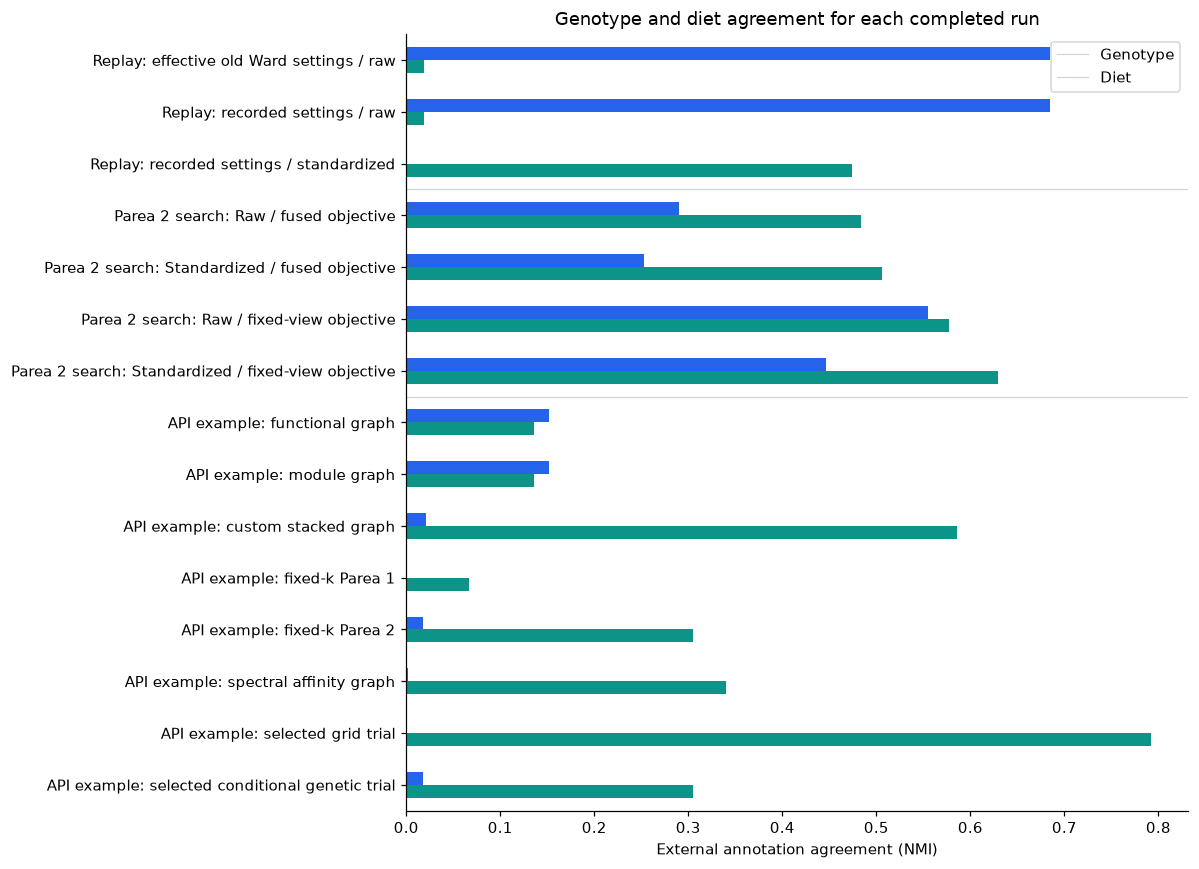

In [22]:
completed_outputs = {
    'Replay: effective old Ward settings / raw': historical_output,
    'Replay: recorded settings / raw': reference_output,
    'Replay: recorded settings / standardized': reference_scaled_output,
    **{'Parea 2 search: ' + name: output for name, output in protocol_outputs.items()},
    'API example: functional graph': functional_result,
    'API example: module graph': module_result,
    'API example: custom stacked graph': stacked_result,
    'API example: fixed-k Parea 1': parea1_result,
    'API example: fixed-k Parea 2': parea2_result,
    'API example: spectral affinity graph': {
        'labels': spectral_result['labels'],
        'distance': nn.AffinityToDistance()(spectral_result['affinity']),
    },
    'API example: selected grid trial': best_result,
    'API example: selected conditional genetic trial': genetic_output,
}
summary = pd.DataFrame([
    score_output(name, output) for name, output in completed_outputs.items()
]).set_index('experiment')
assert np.isfinite(summary.select_dtypes(include='number')).all().all()
with pd.option_context('display.max_colwidth', None):
    display(summary.round(4))

ax = summary[['NMI_genotype', 'NMI_diet']].plot.barh(
    figsize=(11, 8), color=['#2563eb', '#0d9488'])
ax.invert_yaxis()
for boundary in [2.5, 6.5]:
    ax.axhline(boundary, color='#d1d5db', linewidth=0.8)
plt.xlabel('External annotation agreement (NMI)')
plt.ylabel('')
plt.title('Genotype and diet agreement for each completed run')
plt.legend(['Genotype', 'Diet'])
plt.tight_layout()
plt.show()

### Inspect the replayed baseline's partition and distances

The replay using effective old Ward settings recovers the recorded partition.
The plots below order its fused matrix and the fixed evaluation matrix by that
same partition. Their scales and interpretations differ. A clean fused pattern
describes the ensemble's separation; genotype and diet agreement are evaluated
separately in the table and crosstabs.

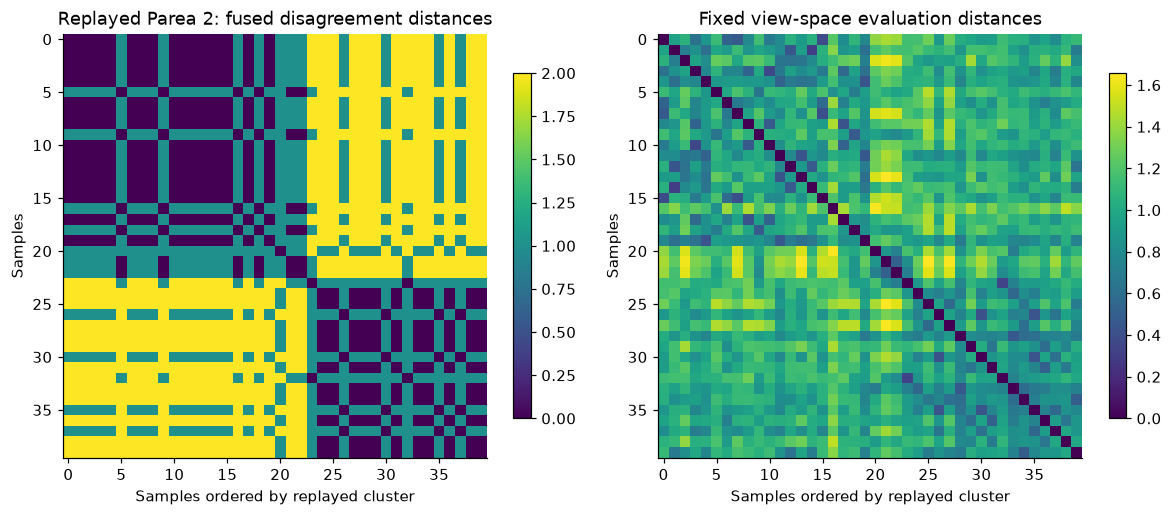

cluster,1,2
genotype,,
ppar,3,17
wt,20,0


cluster,1,2
diet,,
coc,6,2
fish,4,4
lin,4,4
ref,5,3
sun,4,4


Notebook completed: 2 views, 40 samples, 4 Parea 2 search protocols, 24 grid trials, 18 conditional genetic evaluations, 15 reported partitions.


In [23]:
order = np.argsort(historical_output['labels'], kind='stable')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, matrix, title in zip(
    axes, [historical_output['distance'], evaluation_distance],
    ['Replayed Parea 2: fused disagreement distances', 'Fixed view-space evaluation distances'],
):
    image = ax.imshow(matrix[np.ix_(order, order)], cmap='viridis', interpolation='nearest')
    ax.set(title=title, xlabel='Samples ordered by replayed cluster', ylabel='Samples')
    fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

replayed_partition = pd.Series(historical_output['labels'], index=sample_ids, name='cluster')
display(pd.crosstab(genotype, replayed_partition))
display(pd.crosstab(diet, replayed_partition))
print('Notebook completed: {} views, {} samples, {} Parea 2 search protocols, '
      '{} grid trials, {} conditional genetic evaluations, {} reported partitions.'.format(
    len(inputs), len(gene), len(protocol_searches), len(trials),
    genetic.n_evaluations, len(completed_outputs)))

## What to change next

- Keep the raw-data Parea 2 replay as a reference when changing preprocessing or objectives.
- Compare multiple predeclared seeds when assessing search performance.
- Add another `nn.Input` and its preprocessing/clustering branch for a new view.
- Connect the same symbolic result to several blocks to share intermediate work.
- Build reusable submodules and call them from a larger module's `forward()`.
- Replace a leaf operation with a custom `nn.Block` or `nn.Function`.
- Extend the conditional genetic search space, keeping selection separate from evaluation labels.
- Inspect `model.graph` with NetworkX; rebuild the symbolic topology when changing connections.

The graph API executes DAGs sequentially in dependency order. It supports arbitrary
branching and layering, but cycles and automated topology search are not included.
The parameter exercise uses the same data for clustering and internal scoring;
external replication or stability analysis would be needed for stronger scientific
claims. The dataset contains 40 mice, not cancer patients.

## References

- [Original Pyrea Nutrimouse notebook](Nutrimouse.ipynb).
- Pfeifer, Bloice and Schimek (2023), *Parea: Multi-view ensemble clustering for
  cancer subtype discovery*. https://doi.org/10.1016/j.jbi.2023.104406
- Martin et al. (2007), *Novel aspects of PPARalpha-mediated regulation of lipid
  and xenobiotic metabolism revealed through a nutrigenomic study*.
  https://doi.org/10.1002/hep.21510
- Gonzalez et al. (2008), *CCA: An R Package to Extend Canonical Correlation Analysis*.
  https://doi.org/10.18637/jss.v023.i12
- [Bundled dataset provenance and attribution](data/nutrimouse/README.md).
- [Graph API guide](../docs/source/graphs.rst).